# Génération, Split, Standardisation
Partie A1 : données `make_moons`, split train/val/test (60/20/20), standardisation avec les stats du train uniquement.

Le code réutilisable est dans `src/data.py` ; ce notebook sert à visualiser et vérifier.

In [3]:
%load_ext autoreload
%autoreload 2

import sys; sys.path.append("..")
import numpy as np
import matplotlib.pyplot as plt
from src.data import generate_data, split_data, standardize, load_data

SEED = 42
np.random.seed(SEED)

## 1. Génération et dimensions

In [4]:
X, y = generate_data(n_samples=1500, noise=0.20, seed=SEED)
print("X :", X.shape, X.dtype)
print("y :", y.shape, y.dtype, "| classes :", np.unique(y), "| proportion de 1 :", y.mean())

X : (1500, 2) float64
y : (1500,) int64 | classes : [0 1] | proportion de 1 : 0.5


## 2. Visualisation

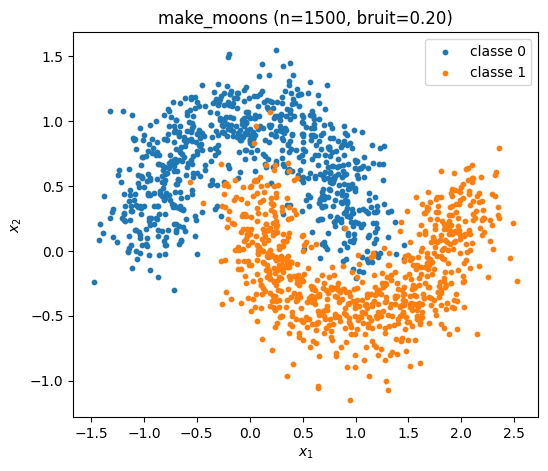

In [5]:
plt.figure(figsize=(6, 5))
plt.scatter(X[y == 0, 0], X[y == 0, 1], s=10, label="classe 0")
plt.scatter(X[y == 1, 0], X[y == 1, 1], s=10, label="classe 1")
plt.title("make_moons (n=1500, bruit=0.20)")
plt.xlabel("$x_1$"); plt.ylabel("$x_2$"); plt.legend(); plt.show()

## 3. Split train / validation / test (60 / 20 / 20)

In [6]:
X_tr, X_va, X_te, y_tr, y_va, y_te = split_data(X, y, seed=SEED)

for name, a, b in [("train", X_tr, y_tr), ("val", X_va, y_va), ("test", X_te, y_te)]:
    print(f"{name:5s} : X {a.shape}, y {b.shape}, proportion de 1 = {b.mean():.3f}")

train : X (900, 2), y (900,), proportion de 1 = 0.500
val   : X (300, 2), y (300,), proportion de 1 = 0.500
test  : X (300, 2), y (300,), proportion de 1 = 0.500


## 4. Standardisation (statistiques du train uniquement)
Les stats de val/test n'interviennent jamais, pour éviter toute fuite d'information.

In [7]:
X_tr_s, X_va_s, X_te_s, mu, sigma = standardize(X_tr, X_va, X_te)

print("mu, sigma (train) :", mu.round(3), sigma.round(3))
print("train : moyenne", X_tr_s.mean(axis=0).round(4), "| écart-type", X_tr_s.std(axis=0).round(4))
print("val   : moyenne", X_va_s.mean(axis=0).round(3), "| écart-type", X_va_s.std(axis=0).round(3))
print("test  : moyenne", X_te_s.mean(axis=0).round(3), "| écart-type", X_te_s.std(axis=0).round(3))

mu, sigma (train) : [0.49  0.245] [0.886 0.529]
train : moyenne [-0. -0.] | écart-type [1. 1.]
val   : moyenne [-0.011  0.066] | écart-type [1.012 1.038]
test  : moyenne [0.091 0.051] | écart-type [0.994 1.05 ]


## 5. Avant / après standardisation

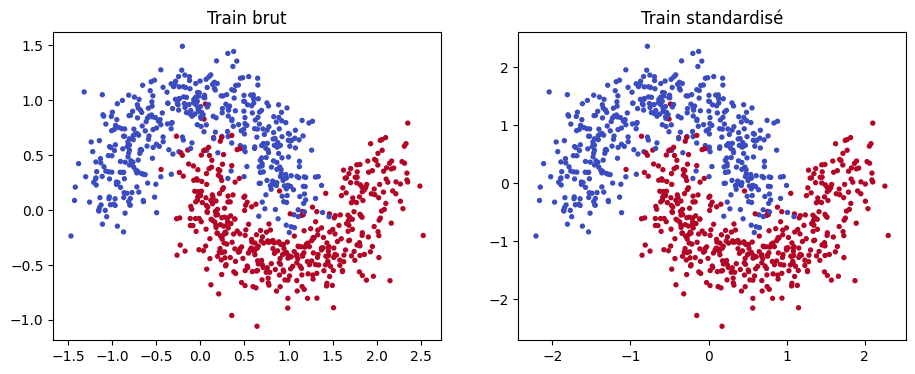

In [8]:
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
ax[0].scatter(X_tr[:, 0], X_tr[:, 1], c=y_tr, s=8, cmap="coolwarm"); ax[0].set_title("Train brut")
ax[1].scatter(X_tr_s[:, 0], X_tr_s[:, 1], c=y_tr, s=8, cmap="coolwarm"); ax[1].set_title("Train standardisé")
plt.show()

## 6. Pipeline complet (utilisé par les autres notebooks)

In [9]:
data = load_data(seed=SEED)
print({k: v.shape for k, v in data.items()})
assert np.allclose(data["X_train"], X_tr_s)  # cohérence avec les étapes manuelles

{'X_train': (900, 2), 'y_train': (900, 1), 'X_val': (300, 2), 'y_val': (300, 1), 'X_test': (300, 2), 'y_test': (300, 1), 'mu': (2,), 'sigma': (2,)}
